# Evaluating individual-level age prediction

Load the released OneK1K model and compute predictions from 500-cell donor inputs.

In [1]:
import warnings
warnings.filterwarnings('ignore', message='IProgress not found.*')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scdecage.tutorials_utils.plotting import DATA_ROOT, setup, output, show_figure
EVALUATION_OUTPUT = Path('outputs/evaluation')
setup()

Extract the Zenodo data and set `SCDECAGE_RELEASE_DATA` to its `data` directory.

## Donor predictions

In [2]:
from scdecage.tutorials_utils.inference import load_analysis_model, infer_donor
CHECKPOINT = DATA_ROOT / 'OneK1K/model.pth'
model, donor_data = load_analysis_model('OneK1K', checkpoint=CHECKPOINT)
rows = []
for item in donor_data:
    *_, result = infer_donor(model, item)
    rows.append({'donor_id': item['donor_id'], 'age_years': float(item['age']),
                 'predicted_age': float(result['pred_age'])})
predictions = pd.DataFrame(rows)

## Summarize metrics

In [3]:
from scipy.stats import pearsonr, spearmanr
observed = predictions.age_years.to_numpy()
predicted = predictions.predicted_age.to_numpy()
metrics = {'Donors': len(predictions), 'MAE': np.mean(np.abs(observed - predicted)),
           'PearsonR': pearsonr(observed, predicted).statistic,
           'SpearmanR': spearmanr(observed, predicted).statistic}
display(pd.Series(metrics, name='Test metric').to_frame())

,Test metric
Donors,197.000000
MAE,8.107989
PearsonR,0.777365
SpearmanR,0.740527


## Plot predictions

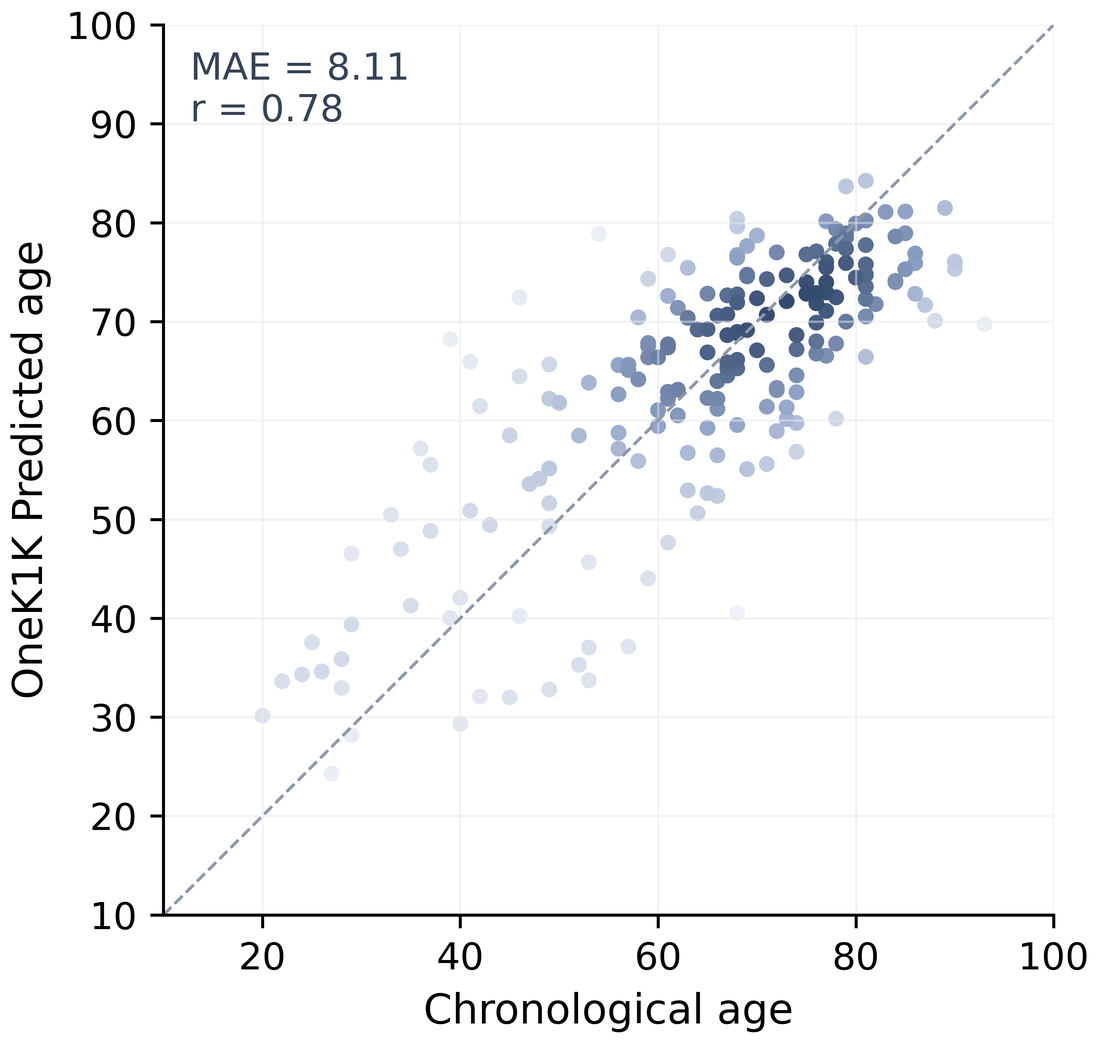

In [4]:
from scipy.stats import gaussian_kde
from matplotlib.colors import LinearSegmentedColormap
x = predictions['age_years'].to_numpy()
y = predictions['predicted_age'].to_numpy()
density = gaussian_kde(np.vstack([x, y]))(np.vstack([x, y]))
order = np.argsort(density)
palette = LinearSegmentedColormap.from_list('prediction_density', ['#EEF1F7', '#92A6C9', '#344B70'])
fig, ax = plt.subplots(figsize=(4.3, 4.3))
ax.scatter(x[order], y[order], c=density[order], cmap=palette, s=18, edgecolors='none')
ax.plot([10, 100], [10, 100], '--', color='#8D98A8', linewidth=0.8)
ax.set(xlim=(10, 100), ylim=(10, 100), xlabel='Chronological age', ylabel='OneK1K Predicted age', aspect='equal')
ax.text(0.03, 0.97, f"MAE = {metrics['MAE']:.2f}\nr = {metrics['PearsonR']:.2f}", transform=ax.transAxes, va='top', fontsize=10, color='#344356')
ax.grid(alpha=0.5)
output(fig, EVALUATION_OUTPUT, 'Prediction_example')
show_figure(EVALUATION_OUTPUT / 'Prediction_example.png')
